# Bibliotecas e setup

## Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima_process import ArmaProcess
import warnings
warnings.filterwarnings('ignore')

## Parâmetros para Gráficos

In [2]:
RED,BLUE,GREEN,GRAY,YELLOW='#E4002B','#1a6fc4','#1a9b57','#555555','#cc8800'

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor':'#FFFFFF','axes.facecolor':'#F9F9F9',
    'axes.edgecolor':'#BBBBBB','axes.labelcolor':'#1C1C1C',
    'xtick.color':'#444444','ytick.color':'#444444',
    'text.color':'#1C1C1C','grid.color': '#DDDDDD',
    'grid.linestyle':'--','grid.alpha':0.5,'figure.dpi':110,
})

# Criação do Dataframe

## Carregando a base PMC

A base já foi pré-processada para conter apenas as colunas relevantes, e já no formato "long" (uma linha por data + UF). O nome da coluna de data é "data", e a coluna de interesse (índice de volume) é "volume_idx". A coluna "uf" indica a Unidade da Federação.

In [3]:
pmc = pd.read_csv("https://github.com/padsInsper/202634-fa/releases/download/data/pmc_volume_uf.csv")

## Escolha sua UF

In [4]:
MINHA_UF = 'Minas Gerais'

In [5]:
df_sf = (
    pmc.query("uf == @MINHA_UF")
    .rename(columns={"uf": "unique_id", "data": "ds", "volume_idx": "y"})
    [["ds", "y", "unique_id"]]
    .reset_index(drop=True)
)

df_sf.head()

,ds,y,unique_id
0,2004-01-01,47.04283,Minas Gerais
1,2004-02-01,43.47343,Minas Gerais
2,2004-03-01,49.05633,Minas Gerais
3,2004-04-01,48.69024,Minas Gerais
4,2004-05-01,49.33090,Minas Gerais


## Preparação da série

In [6]:
df_sf = df_sf.set_index('ds')
df_sf.index = pd.to_datetime(df_sf.index)
df_sf.head()

,y,unique_id
ds,,
2004-01-01,47.04283,Minas Gerais
2004-02-01,43.47343,Minas Gerais
2004-03-01,49.05633,Minas Gerais
2004-04-01,48.69024,Minas Gerais
2004-05-01,49.33090,Minas Gerais


In [7]:
col = df_sf.columns[0]

In [8]:
# Crio defasagem e 1ª diferença
df_sf['y_lag1'] = df_sf['y'].shift(1)
df_sf['y_diff1'] = df_sf['y'].diff(1)
df_sf['y_lag2'] = df_sf['y'].shift(2)
df_sf['y_diff2'] = df_sf['y'].diff(2)
diff1 = df_sf['y_diff1'].dropna()
diff2 = df_sf['y_diff2'].dropna()

In [9]:
# Diferenciação sazonal - Variação mensal menos a de 12 meses antes
df_sf['y_diff_sazonalidade'] = df_sf['y_diff1'].diff(12)

In [10]:
df_sf

,y,unique_id,y_lag1,y_diff1,y_lag2,y_diff2,y_diff_sazonalidade
ds,,,,,,,
2004-01-01,47.04283,Minas Gerais,NaN,NaN,NaN,NaN,NaN
2004-02-01,43.47343,Minas Gerais,47.04283,-3.56940,NaN,NaN,NaN
2004-03-01,49.05633,Minas Gerais,43.47343,5.58290,47.04283,2.01350,NaN
2004-04-01,48.69024,Minas Gerais,49.05633,-0.36609,43.47343,5.21681,NaN
2004-05-01,49.33090,Minas Gerais,48.69024,0.64066,49.05633,0.27457,NaN
...,...,...,...,...,...,...,...
2025-10-01,110.41414,Minas Gerais,106.17128,4.24286,102.12687,8.28727,-1.16600
2025-11-01,108.65351,Minas Gerais,110.41414,-1.76063,106.17128,2.48223,-1.82068
2025-12-01,119.81690,Minas Gerais,108.65351,11.16339,110.41414,9.40276,5.29038


# 1. Análise descritiva

## 1.1 Inspeção visual

Iniciando com um processo de inspeção visual, observa-se:
1. Uma subida acentuada do índice entre 2004 e 2012
2. Um período de movimento lateral entre 2012 e 2015
3. Uma queda em 2016 de cerca de 10 pontos em relação a 2015, patamar em que se manteve até proximo de 2020.
4. Uma recuperação gradual a partir de 2020, com o índice atingindo e superando o patamar de referência (média de 2022 = 100).

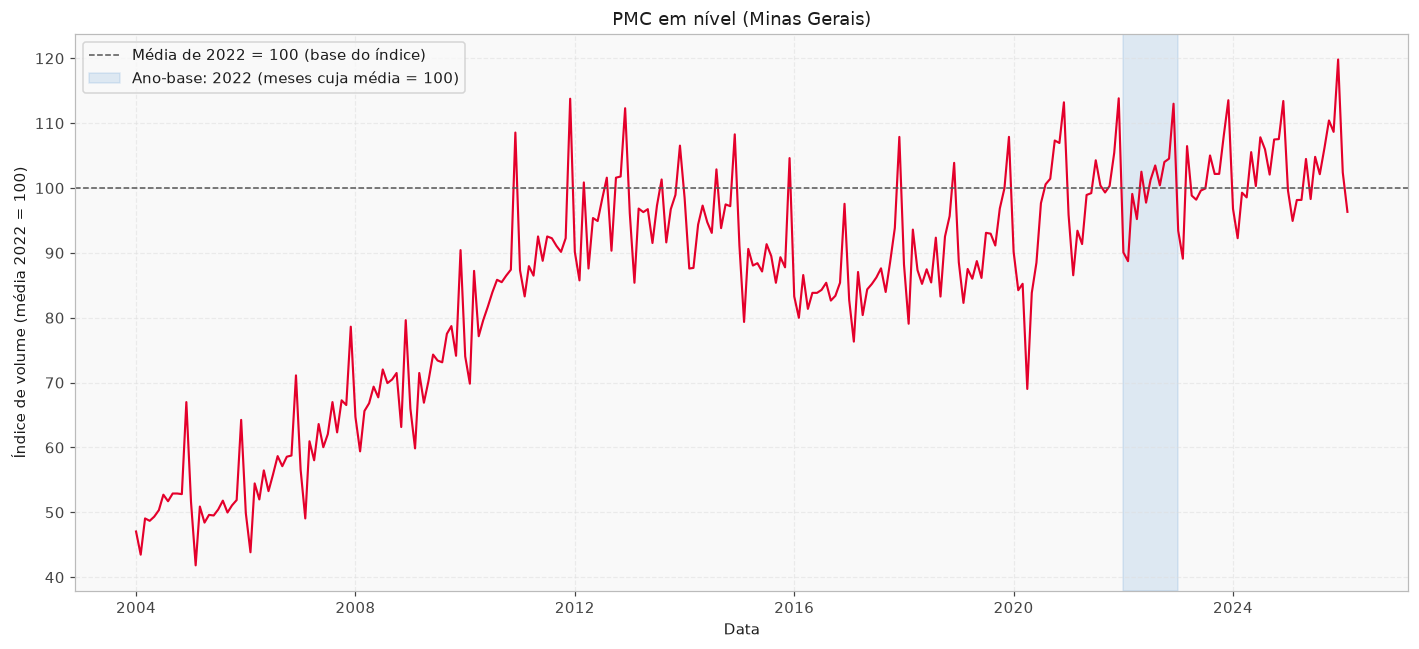

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(df_sf.index, df_sf['y'], color=RED, lw=1.4)

# Base do índice: média de 2022 = 100
ax.axhline(100, color=GRAY, lw=1, ls='--', label='Média de 2022 = 100 (base do índice)')
ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'),
           color=BLUE, alpha=0.12, label='Ano-base: 2022 (meses cuja média = 100)')

ax.set_title(f'PMC em nível ({MINHA_UF})')
ax.set_xlabel('Data')
ax.set_ylabel('Índice de volume (média 2022 = 100)')
ax.legend(loc='upper left')
ax.grid(True)

plt.tight_layout()
plt.show()

## 1.2 Decomposição

Pela análise anterior, observa-se que a **amplitude** entre os picos e vales da série original se mantém aproximadamente **constante** ao longo do tempo. Dessa forma, utilizo a **decomposição aditiva** na análise abaixo.

Adicionalmente, verifica-se que:
1. O gráfico de **tendência** acompanha o ciclo identificado na análise descritiva visual.
2. O gráfico de **sazonalidade** aponta para uma queda acentuada no início do ano (fevereiro), uma recuperação ao longo dos meses seguintes e um pico em dezembro, o que está alinhado ao padrão típico do varejo, especialmente por conta das vendas de fim de ano.
3. O gráfico de **resíduo** aponta para choques pontuais, com destaque para a crise de 2008 (menor impacto) e, principalmente, a COVID em 2020.

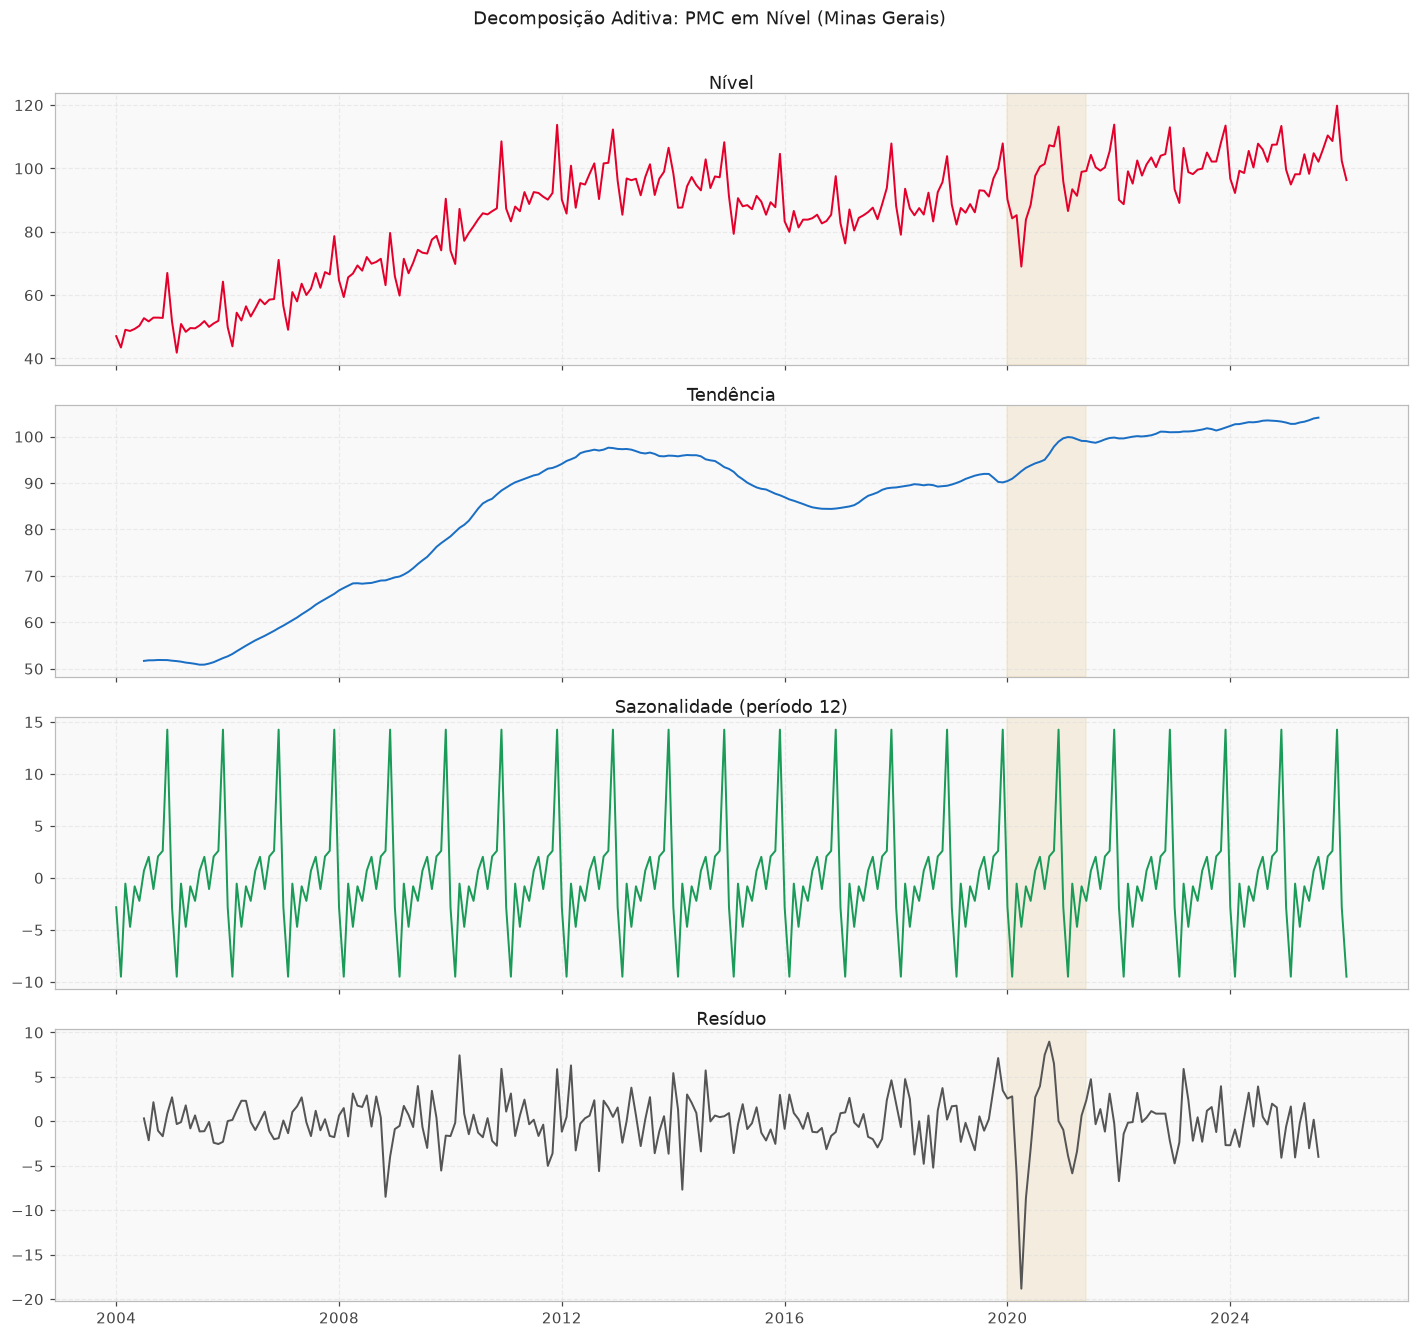

In [12]:
# Utilizo a decomposição aditiva porque a diferença entre os picos e vales da série original se mantêm constantes ao longo do tempo.

decomp = seasonal_decompose(df_sf['y'], model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
for ax, (comp, color, label) in zip(axes, [
    (decomp.observed,  RED,   'Nível'),
    (decomp.trend,     BLUE,  'Tendência'),
    (decomp.seasonal,  GREEN, 'Sazonalidade (período 12)'),
    (decomp.resid,     GRAY,  'Resíduo'),
]):
    ax.plot(comp, color=color, lw=1.3)
    ax.set_title(label, pad=2); ax.grid(True)
    ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'),
               alpha=0.1, color=YELLOW)
fig.suptitle(f'Decomposição Aditiva: PMC em Nível ({MINHA_UF})', fontsize=12, y=1.01)
plt.tight_layout();
plt.show()

## 1.3 Autocorrelação da série em nível

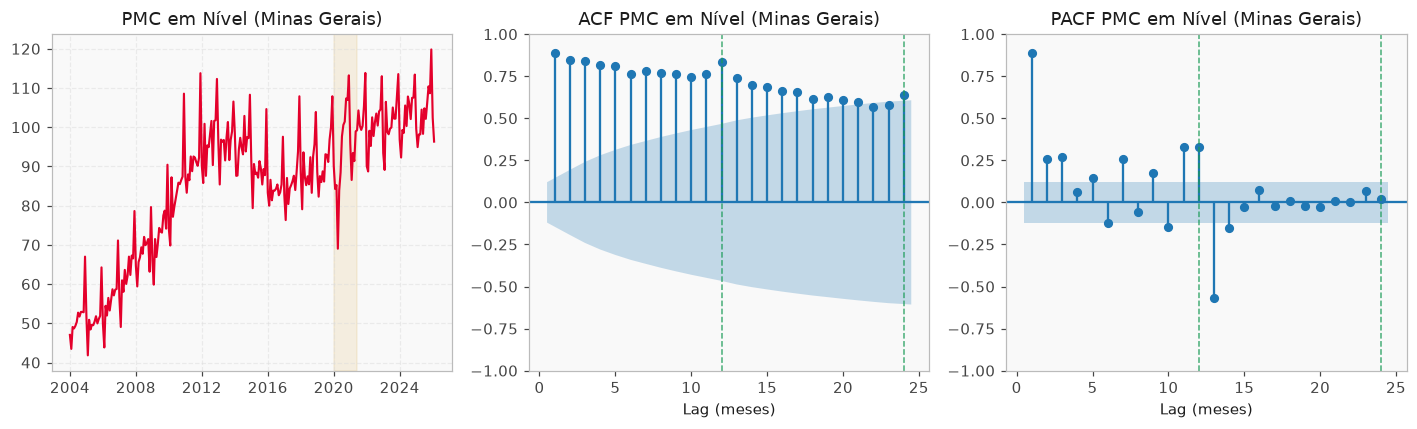

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(df_sf.index, df_sf[col], color=RED, lw=1.4)
axes[0].set_title(f'PMC em Nível ({MINHA_UF})')
axes[0].grid(True)

plot_acf(df_sf[col], ax=axes[1], lags=24, zero=False, title=f'ACF PMC em Nível ({MINHA_UF})')
axes[1].set_xlabel('Lag (meses)')
axes[1].axvline(12, color=GREEN, lw=1, ls='--', alpha=0.8)
axes[1].axvline(24, color=GREEN, lw=1, ls='--', alpha=0.8)
# A diferenca está fora da zona sombreada, logo não é apenas ruído branco
# Observam-se movimentos positivos em 12 e 24, e de maior queda em 6 e 18
# É necessário estacionar a série

plot_pacf(df_sf[col], ax=axes[2], lags=24, zero=False, title=f'PACF PMC em Nível ({MINHA_UF})')
axes[2].set_xlabel('Lag (meses)')
axes[2].axvline(12, color=GREEN, lw=1, ls='--', alpha=0.8)
axes[2].axvline(24, color=GREEN, lw=1, ls='--', alpha=0.8)

axes[0].axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'), alpha=0.1, color=YELLOW)

plt.tight_layout()
plt.show()

> ✏️ **A fazer:** interpretar o ACF e o PACF do nível (decaimento do ACF, lag 1 do PACF, picos sazonais em 12/24, necessidade de estacionarizar).

# 2. Testes de raiz unitária

## 2.1 ADF

In [14]:
def rodar_adf(serie, nome):
    """Teste ADF com resultado formatado."""
    serie = serie.dropna()
    k = int(np.floor((len(serie) - 1) ** (1/3)))
    res = adfuller(serie, maxlag=k, autolag=None, regression='c')
    conclusao = "✅ Rejeita H₀ → ESTACIONÁRIA" if res[1] < 0.05 else "⚠️  Não rejeita H₀ → RAIZ UNITÁRIA"
    print(f"{'='*50}")
    print(f"ADF: {nome}")
    print(f"{'='*50}")
    print(f"  Estatística ADF : {res[0]:.4f}")
    print(f"  p-value         : {res[1]:.4f}")
    print(f"  Lags usados     : {res[2]}")
    print(f"  Valores críticos:")
    for nivel, valor in res[4].items():
        print(f"    {nivel}: {valor:.4f}")
    print(f"  → {conclusao}\n")
    return res[1]

In [15]:
p1 = rodar_adf(df_sf['y']                   ,f'PMC ({MINHA_UF}), Nível')
p3 = rodar_adf(df_sf['y_diff1']             ,f'PMC ({MINHA_UF}), Diff')
p2 = rodar_adf(df_sf['y_diff_sazonalidade'] ,f'PMC ({MINHA_UF}), Diff + Diff Sazonal')

ADF: PMC (Minas Gerais), Nível
  Estatística ADF : -1.8197
  p-value         : 0.3707
  Lags usados     : 6
  Valores críticos:
    1%: -3.4559
    5%: -2.8728
    10%: -2.5728
  → ⚠️  Não rejeita H₀ → RAIZ UNITÁRIA

ADF: PMC (Minas Gerais), Diff
  Estatística ADF : -8.9624
  p-value         : 0.0000
  Lags usados     : 6
  Valores críticos:
    1%: -3.4560
    5%: -2.8728
    10%: -2.5728
  → ✅ Rejeita H₀ → ESTACIONÁRIA

ADF: PMC (Minas Gerais), Diff + Diff Sazonal
  Estatística ADF : -8.5721
  p-value         : 0.0000
  Lags usados     : 6
  Valores críticos:
    1%: -3.4572
    5%: -2.8734
    10%: -2.5731
  → ✅ Rejeita H₀ → ESTACIONÁRIA



## 2.2 KPSS

In [16]:
# A fazer: teste KPSS (nível, 1ª diferença, diferença + diferença sazonal)


> ✏️ **A fazer:** interpretar o KPSS (atenção: H₀ é estacionariedade, o contrário do ADF).

## 2.3 Número de diferenças (`ndiffs` / `nsdiffs`)

In [17]:
# A fazer: ndiffs e nsdiffs


> ✏️ **A fazer:** conclusão dos testes: quantas diferenças regulares (d) e sazonais (D) são necessárias?

# 3. Diferenciação

## 3.1 1ª diferença

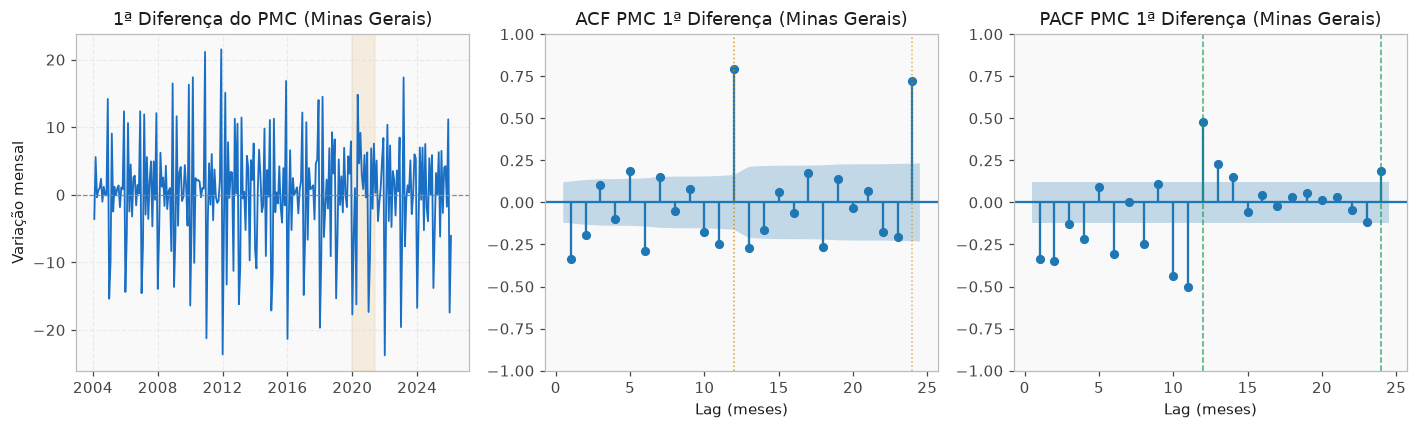

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].plot(diff1.index, diff1, color=BLUE, lw=1.2)
axes[0].axhline(0, color='#888', ls='--', lw=0.8)
axes[0].set_title(f'1ª Diferença do PMC ({MINHA_UF})')
axes[0].set_ylabel('Variação mensal')
axes[0].grid(True)

plot_acf(diff1, ax=axes[1], lags=24, zero=False, title=f'ACF PMC 1ª Diferença ({MINHA_UF})')
axes[1].set_xlabel('Lag (meses)')
axes[1].axvline(12, color=YELLOW, lw=1, ls=':', alpha=0.8)
axes[1].axvline(24, color=YELLOW, lw=1, ls=':', alpha=0.6)
# Quase nao há queda entre os picos sazonais
# A 1ª diferença já removeu a tendência. 
# Agora, os primeiros lags já estão pequenos e alternando de sinal
# A tendência foi removida, agora há apenas os picos de sazonalidade.

plot_pacf(diff1, ax=axes[2], lags=24, zero=False, title=f'PACF PMC 1ª Diferença ({MINHA_UF})')
axes[2].set_xlabel('Lag (meses)')
axes[2].axvline(12, color=GREEN, lw=1, ls='--', alpha=0.8)
axes[2].axvline(24, color=GREEN, lw=1, ls='--', alpha=0.8)

axes[0].axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-06-01'), alpha=0.1, color=YELLOW)

plt.tight_layout()
plt.show()

> ✏️ **A fazer:** interpretar: o que a 1ª diferença removeu e o que ainda permanece (sazonalidade).

## 3.2 Diferença sazonal (série estacionarizada)

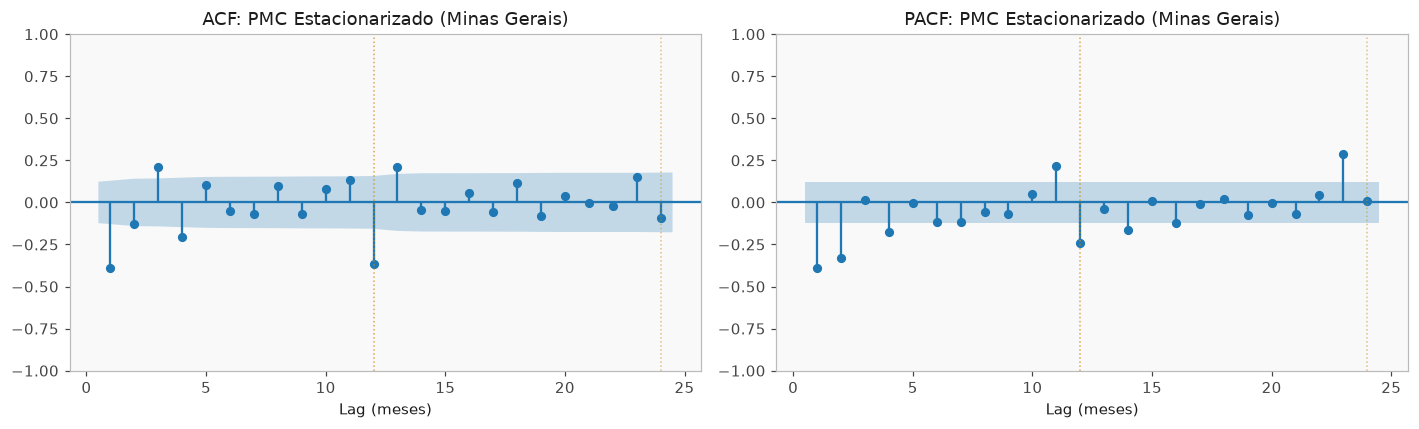

In [19]:
df_sf_est = df_sf['y_diff_sazonalidade'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf( df_sf_est, ax=axes[0], lags=24, zero=False,
          title=f'ACF: PMC Estacionarizado ({MINHA_UF})')
plot_pacf(df_sf_est, ax=axes[1], lags=24, zero=False,
          title=f'PACF: PMC Estacionarizado ({MINHA_UF})')
for ax in axes:
    ax.set_xlabel('Lag (meses)')
    ax.axvline(12, color=YELLOW, lw=1, ls=':', alpha=0.7)
    ax.axvline(24, color=YELLOW, lw=1, ls=':', alpha=0.5)
plt.tight_layout(); plt.show()

**Parte não sazonal (p, q):** olhe só os lags pequenos, 1, 2, 3... (dentro do ciclo de 12).
- ACF: Há apenas uma medição que estoura a bolha. Chuto, portanto, q=1.
- PACF: Há duas medições que estouram a bolha. Chuto, portanto, p=2.

**Parte sazonal (P, Q):** olhe só os lags múltiplos de 12, ou seja, 12, 24, 36.
- ACF: Há apenas uma medição que sai da faixa azul. Chuto, portanto, Q=1.
- PACF: Há apenas uma medição que sai da faixa azul (lag12). Chuto, portanto, P=1.



# 4. Ajuste do SARIMA (AutoARIMA)

In [20]:
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA

# Preparar dados no formato Nixtla
df_sf_sarima = df_sf[['y']].reset_index()
df_sf_sarima.columns = ['ds', 'y']
df_sf_sarima['unique_id'] = MINHA_UF

sf = StatsForecast(
    models=[AutoARIMA(season_length=12)],
    freq='MS',
    n_jobs=1,
)
sf.fit(df=df_sf_sarima)

# Inspecionar modelo selecionado
modelo = sf.fitted_[0, 0].model_
arma   = modelo['arma']  # [p, q, P, Q, s, d, D]
p, q, P, Q, s, d, D = arma
print(f"✅ Modelo selecionado: SARIMA({p},{d},{q})({P},{D},{Q})[{s}]")
print(f"   AIC  : {modelo['aic']:.3f}")
print(f"   BIC  : {modelo['bic']:.3f}")
print(f"   sigma: {modelo['sigma2']**0.5:.4f}")

✅ Modelo selecionado: SARIMA(3,1,2)(1,1,1)[12]
   AIC  : 1357.274
   BIC  : 1385.542
   sigma: 3.3765


> ✏️ **A fazer:** comparar o modelo escolhido pelo AutoARIMA com a proposta manual (p, q, P, Q) e com o d/D indicado pelos testes.

# 5. Diagnóstico dos resíduos

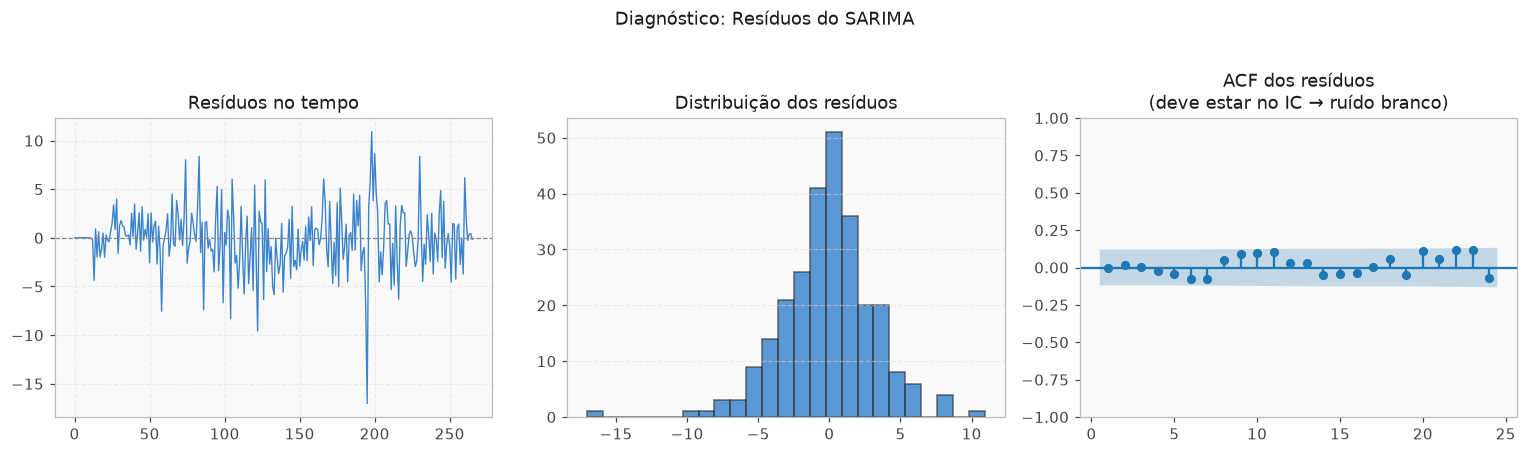

Teste Ljung-Box, p-value: 0.1891
✅ Resíduos são ruído branco!


In [21]:
# Diagnóstico: resíduos do modelo SARIMA
residuos = pd.Series(modelo.get('residuals', []))

if len(residuos) > 10:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].plot(residuos.values, color=BLUE, lw=0.9, alpha=0.85)
    axes[0].axhline(0, color='#888', ls='--', lw=0.8)
    axes[0].set_title('Resíduos no tempo'); axes[0].grid(True)
    axes[1].hist(residuos, bins=25, color=BLUE, alpha=0.7, edgecolor='#333')
    axes[1].set_title('Distribuição dos resíduos'); axes[1].grid(True, axis='y')
    plot_acf(residuos, ax=axes[2], lags=24, zero=False,
             title='ACF dos resíduos\n(deve estar no IC → ruído branco)')
    plt.suptitle('Diagnóstico: Resíduos do SARIMA', fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()

    lb = acorr_ljungbox(residuos, lags=[24], return_df=True)
    pval = lb['lb_pvalue'].values[0]
    print(f"Teste Ljung-Box, p-value: {pval:.4f}")
    print("✅ Resíduos são ruído branco!" if pval > 0.05 else "⚠️  Revisar modelo")
else:
    print("(Resíduos não disponíveis nesta versão do statsforecast)")


> ✏️ **A fazer:** interpretar os resíduos (ACF, distribuição, Ljung-Box).

# 6. Previsão: 24 meses à frente

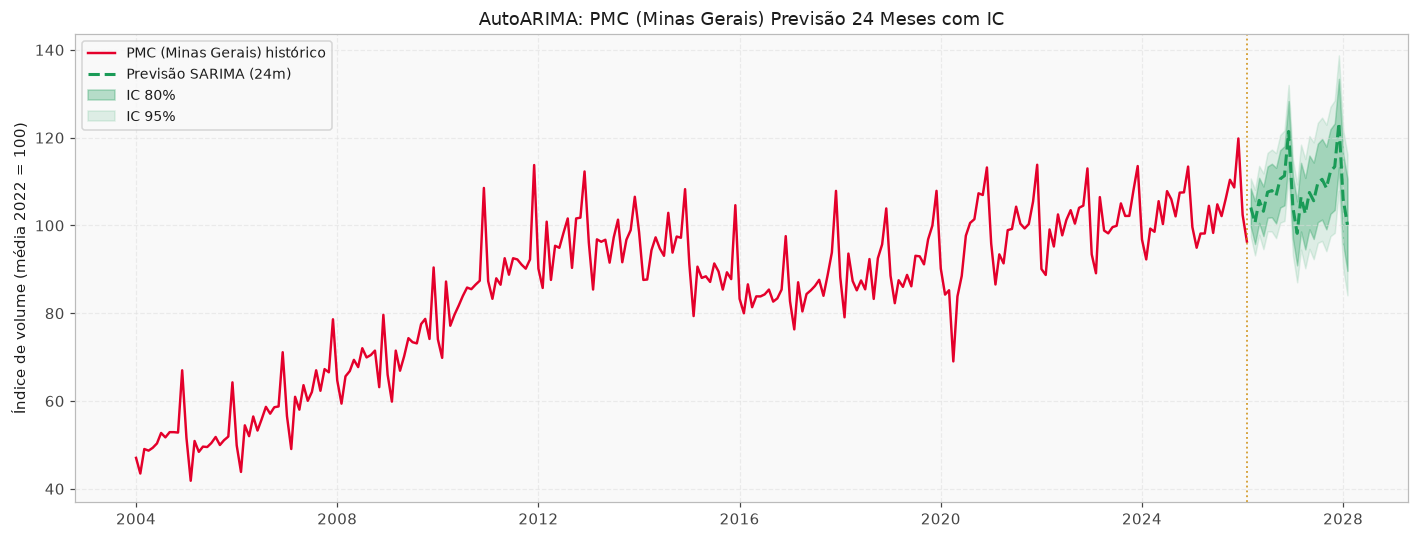

In [22]:
# Previsão 12 meses com IC 80% e 95%
previsao = sf.predict(h=24, level=[80, 95])

fig, ax = plt.subplots(figsize=(13, 5))
# Histórico (últimos 4 anos)
#hist = df_sf['y'].iloc[-48:]
hist = df_sf['y']
ax.plot(hist.index, hist.values, color=RED, lw=1.6, label=f'PMC ({MINHA_UF}) histórico')
ax.plot(previsao['ds'], previsao['AutoARIMA'],
        color=GREEN, lw=2, ls='--', label='Previsão SARIMA (24m)')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-80'], previsao['AutoARIMA-hi-80'],
    color=GREEN, alpha=0.30, label='IC 80%')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-95'], previsao['AutoARIMA-hi-95'],
    color=GREEN, alpha=0.12, label='IC 95%')

ax.axvline(df_sf.index[-1], color=YELLOW, lw=1.2, ls=':', alpha=0.8)
ax.set_title(f'AutoARIMA: PMC ({MINHA_UF}) Previsão 24 Meses com IC')
ax.set_ylabel('Índice de volume (média 2022 = 100)')
ax.legend(fontsize=9); ax.grid(True)
plt.tight_layout(); plt.show()


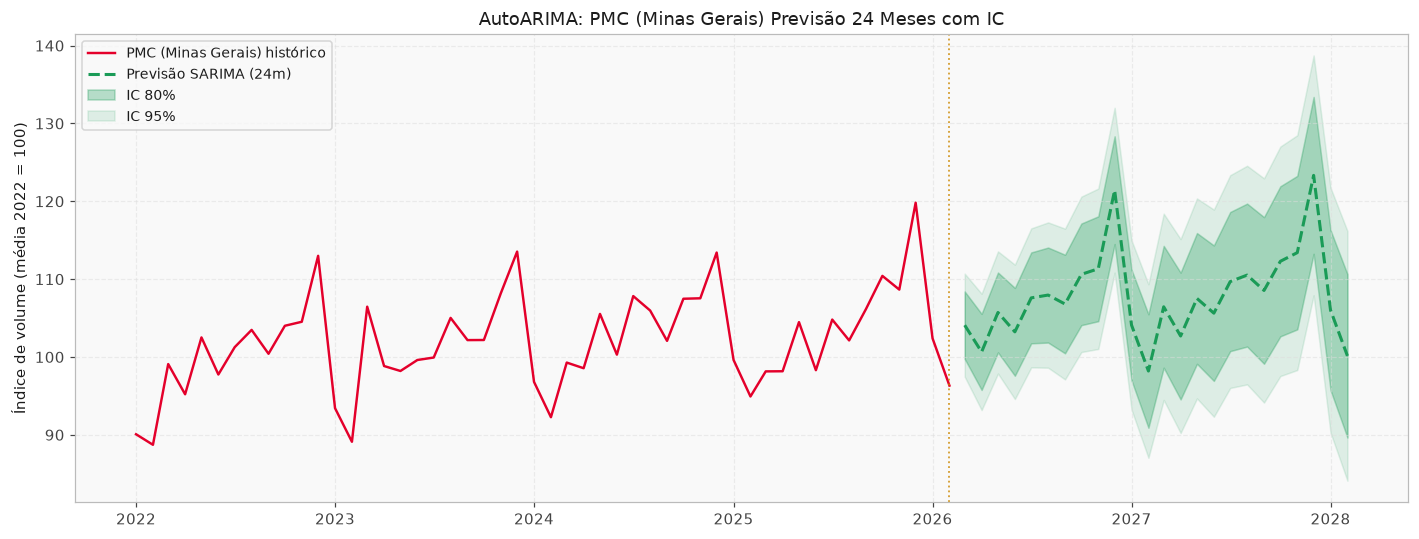

In [23]:
# Previsão 12 meses com IC 80% e 95%
previsao = sf.predict(h=24, level=[80, 95])

fig, ax = plt.subplots(figsize=(13, 5))
# Histórico (últimos 4 anos)
hist = df_sf['y'].iloc[-50:]
ax.plot(hist.index, hist.values, color=RED, lw=1.6, label=f'PMC ({MINHA_UF}) histórico')
ax.plot(previsao['ds'], previsao['AutoARIMA'],
        color=GREEN, lw=2, ls='--', label='Previsão SARIMA (24m)')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-80'], previsao['AutoARIMA-hi-80'],
    color=GREEN, alpha=0.30, label='IC 80%')
ax.fill_between(previsao['ds'],
    previsao['AutoARIMA-lo-95'], previsao['AutoARIMA-hi-95'],
    color=GREEN, alpha=0.12, label='IC 95%')

ax.axvline(df_sf.index[-1], color=YELLOW, lw=1.2, ls=':', alpha=0.8)
ax.set_title(f'AutoARIMA: PMC ({MINHA_UF}) Previsão 24 Meses com IC')
ax.set_ylabel('Índice de volume (média 2022 = 100)')
ax.legend(fontsize=9); ax.grid(True)
plt.tight_layout(); plt.show()


> ✏️ **A fazer:** comentar a previsão (sazonalidade, ancoragem no histórico, abertura dos intervalos).

# 7. Discussão

Escreva 4-5 linhas comentando:

1. O ACF/PACF da série original sugeriu sazonalidade? E tendência? Bate com o que você viu no gráfico de linha?
2. Quantas diferenças (regular e sazonal) o AutoARIMA aplicou? E os componentes AR/MA? Conseguiu observar isso no ACF/PACF?
3. Os resíduos parecem white noise? Algum padrão remanescente sazonal?
4. A previsão pareceu razoável visualmente (captura a sazonalidade, fica bem ancorada no histórico, intervalos abrem muito com o horizonte)?
5. Que outras UFs você imagina que dariam um SARIMA bem diferente do seu (e por quê)? Pense em estados de regiões diferentes, com perfil econômico distinto.


> ✏️ **A fazer:** resposta à pergunta 1.

> ✏️ **A fazer:** resposta à pergunta 2.

> ✏️ **A fazer:** resposta à pergunta 3.

> ✏️ **A fazer:** resposta à pergunta 4.

> ✏️ **A fazer:** resposta à pergunta 5.